In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, json, time
os.chdir('/content/drive/MyDrive/network-intrusion-ml')
sys.path.append('/content/drive/MyDrive/network-intrusion-ml')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from src.utils import (PROCESSED_DIR, METRIC_DIR, TABLE_DIR, FIG_DIR, save_fig, save_table,
                       log_experiment, RANDOM_STATE)
from src.preprocessing import signed_log1p

sns.set_theme(style="whitegrid")

with open(METRIC_DIR / "label_mapping.json") as f:
    label_mapping = json.load(f)
with open(METRIC_DIR / "feature_sets.json") as f:
    feature_sets = json.load(f)

class_names = [c for c, i in sorted(label_mapping.items(), key=lambda kv: kv[1])]
print({k: len(v) for k, v in feature_sets.items() if isinstance(v, list)})

Mounted at /content/drive
{'ALL': 69, 'CORR_FILTERED': 48, 'SELECTED': 25}


In [2]:
from sklearn.model_selection import StratifiedKFold

cv_df = pd.read_parquet(PROCESSED_DIR / "cv_sample.parquet")
y_cv_multi = cv_df["Label_Group"].map(label_mapping).values
y_cv_bin = cv_df["Binary"].values

ALL = feature_sets["ALL"]
CORR = feature_sets["CORR_FILTERED"]
SEL = feature_sets["SELECTED"]
FINGERPRINT = ["Destination Port", "Init_Win_bytes_forward", "Init_Win_bytes_backward"]

CONFIGS = {
    "all": ("ALL features", ALL),
    "corr": ("CORR_FILTERED", CORR),
    "selected": ("SELECTED (top 25)", SEL),
    "no_port": ("CORR_FILTERED minus Destination Port", [c for c in CORR if c != "Destination Port"]),
    "no_fingerprint": ("CORR_FILTERED minus Port and Init_Win_bytes",
                       [c for c in CORR if c not in FINGERPRINT]),
}
for key, (label, cols) in CONFIGS.items():
    print(f"{label:48s} {len(cols)} features")

# Signed-log version of ALL features; each set just picks its columns
X_all_log = pd.DataFrame(signed_log1p(cv_df[ALL].values), columns=ALL).astype("float32")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(skf.split(X_all_log, cv_df["Label_Group"]))      # identical to 06a, 06b, 06c
print("Fold quiz sizes:", [len(va) for _, va in folds])

ALL features                                     69 features
CORR_FILTERED                                    48 features
SELECTED (top 25)                                25 features
CORR_FILTERED minus Destination Port             47 features
CORR_FILTERED minus Port and Init_Win_bytes      45 features
Fold quiz sizes: [101514, 101514, 101514, 101514, 101514]


In [3]:
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score,
                             precision_recall_fscore_support)

SMOTE_TARGET = 2_000
FOLD_CSV = TABLE_DIR / "06d_feature_sets_fold_metrics.csv"

def smote_strategy(y):
    return {c: SMOTE_TARGET for c, n in Counter(y).items() if n < SMOTE_TARGET}

def build_pipeline(use_smote):
    model = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.3,
                          tree_method="hist", n_jobs=-1,
                          random_state=RANDOM_STATE, verbosity=0)
    steps = []
    if use_smote:
        steps.append(("smote", SMOTE(sampling_strategy=smote_strategy, k_neighbors=5,
                                     random_state=RANDOM_STATE)))
    steps.append(("model", model))
    return ImbPipeline(steps)

def run_feature_sets(task):
    """5-fold CV for every clue set. Saved after each set; finished sets are skipped on re-run."""
    rows = pd.read_csv(FOLD_CSV).to_dict("records") if FOLD_CSV.exists() else []
    done = {(r["config"], r["task"]) for r in rows}
    y_all = y_cv_bin if task == "binary" else y_cv_multi

    for key, (label, cols) in CONFIGS.items():
        if (key, task) in done:
            print(f"[skip] {label} / {task} (already saved)")
            continue
        X = X_all_log[cols]
        oof = np.zeros(len(y_all), dtype=np.int8)
        for k, (tr, va) in enumerate(folds, 1):
            model = build_pipeline(use_smote=(task == "multiclass"))
            t0 = time.time()
            model.fit(X.iloc[tr], y_all[tr])
            fit_s = time.time() - t0
            y_v = y_all[va]
            if task == "binary":
                proba = model.predict_proba(X.iloc[va])
                pred = proba.argmax(axis=1)
                m = {"accuracy": accuracy_score(y_v, pred),
                     "precision": precision_score(y_v, pred, zero_division=0),
                     "recall": recall_score(y_v, pred, zero_division=0),
                     "f1": f1_score(y_v, pred, zero_division=0),
                     "roc_auc": roc_auc_score(y_v, proba[:, 1]),
                     "pr_auc": average_precision_score(y_v, proba[:, 1])}
                score_key = "f1"
            else:
                pred = model.predict(X.iloc[va])
                present = np.unique(y_v)
                m = {"accuracy": accuracy_score(y_v, pred),
                     "macro_f1": f1_score(y_v, pred, labels=present, average="macro", zero_division=0),
                     "weighted_f1": f1_score(y_v, pred, average="weighted", zero_division=0)}
                score_key = "macro_f1"
            oof[va] = pred
            rows.append({"config": key, "label": label, "task": task, "n_features": len(cols),
                         "fold": k, "train_seconds": round(fit_s, 1), **m})
            print(f"{label[:44]:44s} {task:10s} fold {k}/5 | fit {fit_s:6.1f}s | {score_key} {m[score_key]:.4f}")

        np.save(METRIC_DIR / f"06d_oof_{key}_{task}.npy", oof)
        pd.DataFrame(rows).to_csv(FOLD_CSV, index=False)
        mine = pd.DataFrame([r for r in rows if r["config"] == key and r["task"] == task])
        log_experiment(
            experiment_id=f"EXP-07_features_{key}_{task}",
            task="Experiment A: binary" if task == "binary" else "Experiment B: multi-class (Label_Group)",
            model="XGBoost (defaults)", features=f"{label} ({len(cols)} features), signed-log transformed",
            preprocessing="SMOTE inside training folds" if task == "multiclass" else "original data",
            hyperparameters="baseline defaults", split="stratified 5-fold CV on the CV sample",
            metrics={k2: round(float(mine[k2].mean()), 4) for k2 in m.keys()},
            notes="Experiment 4: feature-set comparison / shortcut check",
        )
    print("Done:", task)

print("Ready.")

Ready.


In [4]:
run_feature_sets("binary")

ALL features                                 binary     fold 1/5 | fit   18.8s | f1 0.9972
ALL features                                 binary     fold 2/5 | fit   16.0s | f1 0.9965
ALL features                                 binary     fold 3/5 | fit   15.7s | f1 0.9972
ALL features                                 binary     fold 4/5 | fit   16.1s | f1 0.9971
ALL features                                 binary     fold 5/5 | fit   15.5s | f1 0.9973
[logged experiment] EXP-07_features_all_binary
CORR_FILTERED                                binary     fold 1/5 | fit   11.6s | f1 0.9971
CORR_FILTERED                                binary     fold 2/5 | fit   12.5s | f1 0.9965
CORR_FILTERED                                binary     fold 3/5 | fit   12.9s | f1 0.9972
CORR_FILTERED                                binary     fold 4/5 | fit   12.9s | f1 0.9972
CORR_FILTERED                                binary     fold 5/5 | fit   12.7s | f1 0.9974
[logged experiment] EXP-07_features_corr_bi

In [5]:
run_feature_sets("multiclass")

ALL features                                 multiclass fold 1/5 | fit  118.1s | macro_f1 0.9488
ALL features                                 multiclass fold 2/5 | fit  115.3s | macro_f1 0.9810
ALL features                                 multiclass fold 3/5 | fit  115.2s | macro_f1 0.9819
ALL features                                 multiclass fold 4/5 | fit  121.3s | macro_f1 0.9317
ALL features                                 multiclass fold 5/5 | fit  143.0s | macro_f1 0.9746
[logged experiment] EXP-07_features_all_multiclass
CORR_FILTERED                                multiclass fold 1/5 | fit   98.9s | macro_f1 0.9725
CORR_FILTERED                                multiclass fold 2/5 | fit  102.1s | macro_f1 0.9728
CORR_FILTERED                                multiclass fold 3/5 | fit   96.2s | macro_f1 0.9917
CORR_FILTERED                                multiclass fold 4/5 | fit   95.2s | macro_f1 0.9586
CORR_FILTERED                                multiclass fold 5/5 | fit   97.

                                   clue set  features       binary F1   binary recall 10-class macro-F1  pooled macro-F1  Bot F1  Infiltration recall  Heartbleed F1  false alarms (%)  sec/fold (10-class)
                               ALL features        69 0.9971 ± 0.0003 0.9989 ± 0.0003   0.9636 ± 0.0223           0.9650   0.927                0.828          0.900             0.107                122.6
                              CORR_FILTERED        48 0.9971 ± 0.0003 0.9989 ± 0.0003   0.9745 ± 0.0118           0.9746   0.929                0.897          1.000             0.107                 98.0
                          SELECTED (top 25)        25 0.9943 ± 0.0004 0.9970 ± 0.0003   0.7769 ± 0.2165           0.6836   0.534                0.621          0.028             1.426                 60.3
       CORR_FILTERED minus Destination Port        47 0.9961 ± 0.0003 0.9979 ± 0.0001   0.9649 ± 0.0112           0.9644   0.907                0.793          1.000             0.131  

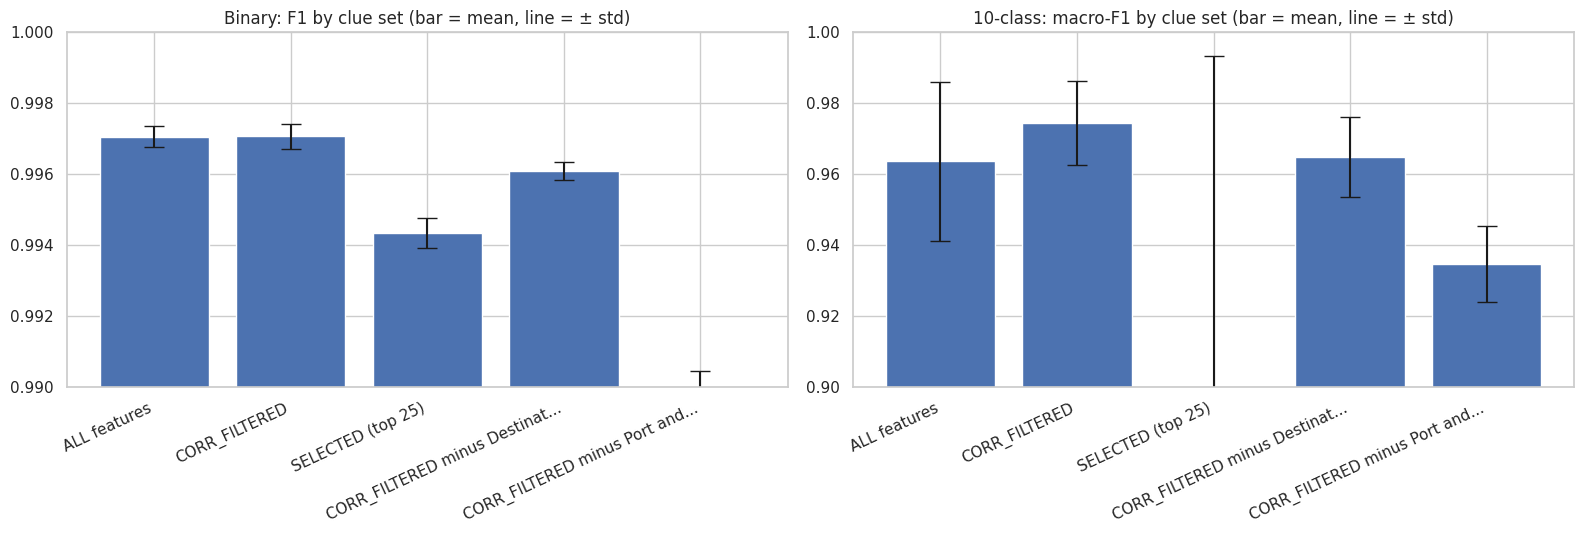

In [6]:
fold_df = pd.read_csv(FOLD_CSV)

def pm(s, nd=4):
    return f"{s.mean():.{nd}f} ± {s.std():.{nd}f}"

rows = []
for key, (label, cols) in CONFIGS.items():
    b = fold_df[(fold_df.config == key) & (fold_df.task == "binary")]
    m = fold_df[(fold_df.config == key) & (fold_df.task == "multiclass")]
    oof = np.load(METRIC_DIR / f"06d_oof_{key}_multiclass.npy")
    p, r, f, s = precision_recall_fscore_support(
        y_cv_multi, oof, labels=list(range(len(class_names))), zero_division=0)
    f1c, rec = dict(zip(class_names, f)), dict(zip(class_names, r))
    rows.append({"clue set": label, "features": len(cols),
                 "binary F1": pm(b["f1"]), "binary recall": pm(b["recall"]),
                 "10-class macro-F1": pm(m["macro_f1"]),
                 "pooled macro-F1": round(float(np.mean(f)), 4),
                 "Bot F1": round(f1c["Bot"], 3),
                 "Infiltration recall": round(rec["Infiltration"], 3),
                 "Heartbleed F1": round(f1c["Heartbleed"], 3),
                 "false alarms (%)": round((1 - rec["BENIGN"]) * 100, 3),
                 "sec/fold (10-class)": round(m["train_seconds"].mean(), 1)})
summary = pd.DataFrame(rows)
print(summary.to_string(index=False))
save_table(summary, "06d_feature_set_comparison", index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
labels = [CONFIGS[k][0] for k in CONFIGS]
for ax, task, col, lo, title in [(axes[0], "binary", "f1", 0.99, "Binary: F1 by clue set"),
                                 (axes[1], "multiclass", "macro_f1", 0.9, "10-class: macro-F1 by clue set")]:
    agg = [fold_df[(fold_df.config == k) & (fold_df.task == task)][col] for k in CONFIGS]
    ax.bar(range(len(agg)), [a.mean() for a in agg], yerr=[a.std() for a in agg],
           capsize=7, color="#4C72B0")
    ax.set_xticks(range(len(agg)))
    ax.set_xticklabels([f"{l[:28]}..." if len(l) > 28 else l for l in labels], rotation=25, ha="right")
    ax.set_ylim(lo, 1.0)
    ax.set_title(title + " (bar = mean, line = ± std)")
save_fig("06d_feature_set_comparison")
plt.show()

In [7]:
cols = ["Total Length of Fwd Packets", "Fwd Packet Length Max", "Average Packet Size", "Flow Bytes/s"]
zero_pct = cv_df.groupby("Label_Group")[cols].agg(lambda s: (s == 0).mean() * 100).round(1)
zero_pct.columns = [f"% rows = 0: {c}" for c in cols]
print("Share of rows where the value is exactly zero, by class:\n")
print(zero_pct.to_string())
save_table(zero_pct, "06d_zero_payload_check")

med = cv_df.groupby("Label_Group")[["Flow Duration", "Total Fwd Packets", "Average Packet Size"]].median().round(1)
print("\nMedian values by class:\n")
print(med.to_string())

Share of rows where the value is exactly zero, by class:

              % rows = 0: Total Length of Fwd Packets  % rows = 0: Fwd Packet Length Max  % rows = 0: Average Packet Size  % rows = 0: Flow Bytes/s
Label_Group                                                                                                                                        
BENIGN                                           13.2                               13.2                             12.6                      12.6
Bot                                              25.9                               25.9                              0.1                       0.1
DDoS                                              0.0                                0.0                              0.0                       0.0
DoS                                               7.9                                7.9                              7.7                       7.7
FTP-Patator                                       0.2 

In [8]:
for p in sorted(TABLE_DIR.glob("06d_*")) + sorted(METRIC_DIR.glob("06d_*")) + sorted(FIG_DIR.glob("06d_*")):
    print(p.name)

06d_feature_set_comparison.csv
06d_feature_sets_fold_metrics.csv
06d_zero_payload_check.csv
06d_oof_all_binary.npy
06d_oof_all_multiclass.npy
06d_oof_corr_binary.npy
06d_oof_corr_multiclass.npy
06d_oof_no_fingerprint_binary.npy
06d_oof_no_fingerprint_multiclass.npy
06d_oof_no_port_binary.npy
06d_oof_no_port_multiclass.npy
06d_oof_selected_binary.npy
06d_oof_selected_multiclass.npy
06d_feature_set_comparison.png
